In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/9/2022
# version ='1.0'

## Demo: The Central Path in Inequality form Linear Programming

In the text book book-convex-2004, section 11.2, the example 11.1 was given to illustrate the geometric interpretation of the centrality conditions in the inequality form liner programming problem,

$$
\begin{array}{rl}
\text{minimize} & c^Tx \\
\text{subject to} & Ax \preceq b \\ 
\end{array}
$$

Accordingly, the logarithmic barrier function is given by 
$$
\phi(x) = -\displaystyle{\sum_{i=1}^{m}\log(b_i-a_i^Tx)}
$$

So, the minimization problem after introducing the barrier function becomes an unconstrained problem as,

\begin{equation}
\begin{array}{rl}
\text{minimize} & tc^Tx+ \phi(x)\\
\end{array}
\label{eq.log}
\end{equation}


The centrality condition is 
\begin{equation}
\begin{array}{c}
tc + \nabla \phi(x) = 0
\end{array}
\end{equation}

Or, in a more compact form,

\begin{equation}
\begin{array}{c}
tc + A^Td  = 0
\end{array}
\label{eq.c}
\end{equation}

because $\nabla \phi(x)=A^Td$, where $d\in R^m$ are given by $d=(\dfrac{1}{b-Ax})$.

%In the above centrality condition, $A^Td$ is derived from $A^Td=\nabla \phi(x)$, where $\phi(x)$ is the logarithmic barrier function given by 
%$$
%\phi(x) = -\displaystyle{\sum_{i=1}^{m}\log(b_i-a_i^Tx)}
%$$

The central path $x^*(t)$ is the series of solutions to equation 1 for any $t>0$.

In the experiment, the central paths for different selection of $c$ are visualized. Attached is the experiment result: (1) $c=[1, 1]$, (2) $c=[-1, -1]$, (3) $c=a_i$ 

In [14]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import math

Calculate the logarithmic barrier function given by
$\phi(x) = -\displaystyle{\sum_{i=1}^{m}\log(b_i-a_i^Tx)}$

In [15]:
def phi(x, A, b):
    """
    Calculation of the logarithmic barrier function given by $\phi(x) = -\displaystyle{\sum_{i=1}^{m}\log(b_i-a_i^Tx)}$
    :param x:
    :param A:
    :param b:
    :return:
    """
    m = len(A)
    n = len(x)
    sum = 0
    with warnings.catch_warnings():
        warnings.filterwarnings('error')
        try:
            for mi in range(m):
                sum += -1 * (np.log(b[mi] - A[mi] @ x))
        except RuntimeWarning as e:  # there may be runtime waring due to $b_i-a_i x < 0$
            return np.nan
    return sum


 For any given value of t, exhaustively search for the solution, $x^*$,
 to satisfy the centrality conditions $tc + A^T d = 0$ (or $c+ \dfrac{A^Td}{t}=0)$,
 where  $d=\text{diag}(\dfrac{1}{b-Ax^*})$, within the range [-X1, X1] and  [-X2, X2]

In [16]:
def search_solver_x(t, c, A, b, X1, X2, dx1, dx2):
    """
    For any given value of t, exhaustively search for the solution, $x^*$,
    to satisfy the centrality conditions $tc + A^T d = 0$ (or $c+ \dfrac{A^Td}{t}=0)$,
    where  $d=\text{diag}(\dfrac{1}{b-Ax^*})$, within the range [-X1, X1] and  [-X2, X2]
    :param t:
    :param c:
    :param A:
    :param b:
    :param X1: The range of x to search is [-X1, X1]
    :param X2: The range of x to search is [-X2, X2]
    :param dx1: The step size in the search direction of the first axis
    :param dx2: The step size in the search direction of the second axis
    :return:
    """
    x1_s = np.linspace(-X1, X1, int(2 * X1 / dx1))
    x2_s = np.linspace(-X2, X2, int(2 * X2 / dx2))
    x1_asterisk = 0
    x2_asterisk = 0
    diff_min = np.inf
    for x1 in x1_s:
        for x2 in x2_s:
            x = np.array([[x1], [x2]])
            if not np.all(b - A @ x > 0):
                continue
            d = 1 / (b - A @ x)
            diff = np.linalg.norm(t * c + A.T @ d)
            if diff < diff_min:
                diff_min = diff
                x1_asterisk = x1
                x2_asterisk = x2
    #if not np.allclose(diff_min / t, 0, atol=1e-1):
    #    raise RuntimeError(r'It is expected that $(c + 1/t A^T d)$ is approaching zero.')
    return np.array([[x1_asterisk], [x2_asterisk]]), diff_min

 To generate the model parameters, A, b, satisfying $\{x|Ax\leq b\}$ is a hexagon.

In [17]:
def generate_model_parameters(m, n, radius, delta, random_seed):
    '''
    To generate the model parameters, A, b, satisfying $\{x|Ax\leq b\}$ is a hexagon.
    :param m:
    :param n:
    :param radius:
    :param delta:
    :param random_seed:
    :return:
    '''
    if not n == 2:
        raise RuntimeError('Only n=2 is supported.')
    A_l = []  # a list saving all a_i, i=1,2,...,m
    b_l = []  # a list saving all b_i, i=1,2,...,m
    np.random.seed(random_seed)

    theta_offset = 2 * math.pi / (2 * m)
    for i in range(m):
        theta = 2 * math.pi / m * i + theta_offset
        ai1 = radius * math.cos(theta) + delta * np.random.uniform(-1, 1)
        ai2 = radius * math.sin(theta) + delta * np.random.uniform(-1, 1)
        bi = radius ** 2

        A_l.append([ai1, ai2])
        b_l.append([bi])

    A = np.array(A_l)
    b = np.array(b_l)
    return A, b

Plot the hexagon defined by $\{x|Ax\leq b\}$

In [18]:
def plot_hexagon(X, Np, A, b, ax):
    '''
    Plot the hexagon defined by $\{x|Ax\leq b\}$
    :param X:
    :param Np:
    :param A:
    :param b:
    :param ax:
    :return:
    '''
    m = A.shape[0]
    # plot the m lines defined by a_ix=b_i
    for i in range(m):
        x = np.linspace(-X, X, Np)
        y = [(b[i] - A[i][0] * xt) / A[i][1] for xt in x]
        ax.plot(x, y, color='C{}'.format(i), linestyle='dashed', label=r'$a_{}x=b_{}$'.format(i, i))
    ax.grid()

 Plot the contour of the barrier function (i.e. $\phi(...)$)

In [19]:
def plot_barrier_contour(Np, X1, X2, A, b, ax):
    '''
    Plot the contour of the barrier function (i.e. $\phi(...)$)
    :param Np:
    :param X1:
    :param X2:
    :param A:
    :param b:
    :param ax:
    :return:
    '''
    x1_s = np.linspace(-X1, X1, Np)
    x2_s = np.linspace(-X2, X2, Np)

    X1_grip, X2_grip = np.meshgrid(x1_s, x2_s)
    Z_grip = np.zeros(X1_grip.shape)
    for x1_i, x1 in enumerate(x1_s):
        for x2_i, x2 in enumerate(x2_s):
            Z_grip[x2_i][x1_i] = phi(np.array([[x1], [x2]]), A, b)

    levels = np.arange(-30, -7, 0.25)
    CS = ax.contour(X1_grip, X2_grip, Z_grip, levels=levels)

    ax.clabel(CS, fontsize=6, inline=True)

In [20]:
def plot_central_path_Inequality_LP(c):
    m = 6
    n = 2
    radius = 8.0
    delta = 1.0
    random_seed = 1

    A, b = generate_model_parameters(m, n, radius, delta, random_seed)
    print('Info: Model parameters, A, b, are generated successfully.')

    X1 = 10  # the search range of x is in [-X1, X1]
    X2 = 10  # the search range of y is in [-X2, X2]
    Np = 100  # number of points to sample in [-X1, X2], [-X2, X2]

    plt.figure(figsize=[9, 9])
    ax = plt.subplot(1, 1, 1)
    ax.set_aspect('equal', 'box')
    ax.set(xlim=(-X1, X1), ylim=(-X2, X2))

    plot_hexagon(X1, Np, A, b, ax)

    t_s = [0.125, 0.25, 0.5, 1, 2, 4, 8, 16, 32]
    x1_asterisk_s = []
    x2_asterisk_s = []

    for t_index, t in enumerate(t_s):
        print(r'Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t={}.'.format(
            t))

        # For solve the centrality condition equation by exhaustive search
        dx1 = 0.05
        dx2 = 0.05
        x_asterisk, diff_min = search_solver_x(t, c, A, b, X1, X2, dx1, dx2)
        x1_asterisk_s.append(x_asterisk[0, 0])
        x2_asterisk_s.append(x_asterisk[1, 0])

        # plot the line $c^Tx$ passing through the x_asterisk point
        x1 = np.linspace(-X1, X1, Np)
        x1_asterisk = x_asterisk[0, 0]
        x2_asterisk = x_asterisk[1, 0]
        ai1 = c[0, 0]
        ai2 = c[1, 0]
        bi = ai1 * x1_asterisk + ai2 * x2_asterisk
        x2 = [(bi - ai1 * xt) / ai2 for xt in x1]
        ax.plot(x1, x2, color='blue', linestyle='dashed')
        # add tags for a selection range of t
        if t_index < 5 or t_index >= 8:
            ax.text(x1_asterisk, x2_asterisk, 't={}'.format(t))

    ax.plot(x1_asterisk_s, x2_asterisk_s, color='red', marker='+')

    Np = 400  # (higher) number of points to sample in [-X1, X2], [-X2, X2]
    plot_barrier_contour(Np, X1, X2, A, b, ax)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title('central path for c=[{:.3f}, {:.3f}]'.format(c[0, 0], c[1, 0]))
    ax.legend()
    plt.show()


In [21]:
import ipywidgets as widgets
from IPython.display import display

In [22]:
wid_dropdown = widgets.Dropdown(
    options=[('[1, 1]', 0), ('[-1, -1]', 1), ('[1, -1]', 2), ('[-1, 1]', 3)],
    value=0,
    description='c = ',
)
output = widgets.Output()
display(wid_dropdown, output)

Dropdown(description='c = ', options=(('[1, 1]', 0), ('[-1, -1]', 1), ('[1, -1]', 2), ('[-1, 1]', 3)), value=0…

Output()

c=[[1]
 [1]]
Info: Model parameters, A, b, are generated successfully.
Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t=0.125.
Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t=0.25.
Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t=0.5.
Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t=1.
Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t=2.
Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t=4.
Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t=8.
Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t=16.
Info: it is solving the centrality condition equation ($tc + A^Td = 0, d=1/(b-Ax))$) with t=32.


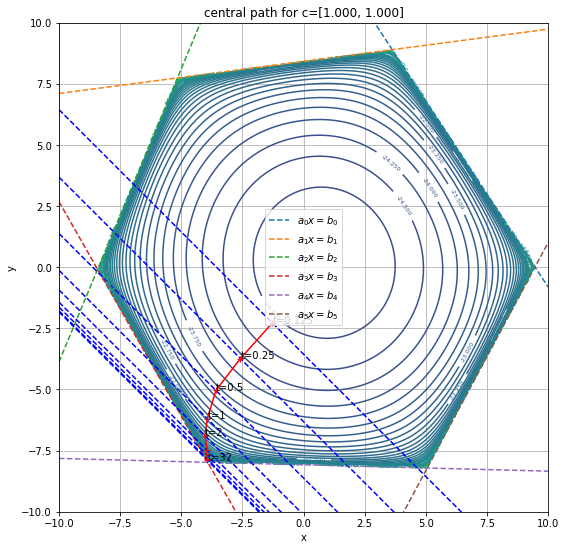

In [23]:
if __name__ == "__main__":
    c = np.array([[1], [1]])
    if wid_dropdown.value == 0:
        c = np.array([[1], [1]])
    elif wid_dropdown.value == 1:
        c = np.array([[-1], [-1]])
    elif wid_dropdown.value == 2:
        c = np.array([[1], [-1]])
    elif wid_dropdown.value == 3:
        c = np.array([[-1], [1]])
    print('c={}'.format(c))
    plot_central_path_Inequality_LP(c)